In [10]:
# Load the four previously created datasets
imperviousness_df = pd.read_csv("merged_complete_datasets/imperviousness_by_lor.csv")
population_df = pd.read_csv("merged_complete_datasets/berlin_neighbourhood_environment_population.csv")
tree_cover_df = pd.read_csv("merged_complete_datasets/tree_cover_comparison.csv")
land_cover_df = pd.read_csv("merged_complete_datasets/berlin_land_cover_by_neighbourhood.csv")

# Inspect their dimensions and column names
datasets = {
    "Imperviousness": imperviousness_df,
    "Population": population_df,
    "Tree cover": tree_cover_df,
    "Land cover": land_cover_df
}

for name, df in datasets.items():
    print(f"\n--- {name} ---")
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    display(df.head(3))


--- Imperviousness ---
Shape: (143, 7)
Columns: ['bzr_id', 'bzr_name', 'bez', 'imperviousness_mean', 'imperviousness_median', 'impervious_pixels_pct', 'pixel_count']


,bzr_id,bzr_name,bez,imperviousness_mean,imperviousness_median,impervious_pixels_pct,pixel_count
0,11001,Tiergarten Süd,01 - Mitte,40.069335,0.0,48.743233,51720
1,11002,Regierungsviertel,01 - Mitte,89.484086,100.0,95.363158,26958
2,11003,Alexanderplatz,01 - Mitte,74.750883,93.0,84.473735,62288



--- Population ---
Shape: (143, 15)
Columns: ['bzr_id', 'bzr_name', 'bez', 'tree_cover_mean', 'tree_cover_median', 'tree_cover_pixels_pct', 'pixel_count', 'imperviousness_mean', 'green_natural', 'population_2025', 'male_population_2025', 'female_population_2025', 'population_complete', 'area_km2', 'population_density_km2']


,bzr_id,bzr_name,bez,tree_cover_mean,tree_cover_median,tree_cover_pixels_pct,pixel_count,imperviousness_mean,green_natural,population_2025,male_population_2025,female_population_2025,population_complete,area_km2,population_density_km2
0,11001,Tiergarten Süd,01 - Mitte,34.611350,0.0,39.338747,51720,40.069335,48.496369,16349.0,8584.0,7765.0,True,5.172416,3160.805245
1,11002,Regierungsviertel,01 - Mitte,0.754692,0.0,1.086876,26958,89.484086,4.922988,13758.0,7056.0,6702.0,True,2.695472,5104.114961
2,11003,Alexanderplatz,01 - Mitte,3.760034,0.0,5.551631,62288,74.750883,4.914470,62409.0,31711.0,30698.0,True,6.228747,10019.510868



--- Tree cover ---
Shape: (143, 9)
Columns: ['bzr_id', 'bzr_name', 'bez', 'tree_cover_mean', 'tree_cover_median', 'tree_cover_pixels_pct', 'pixel_count', 'imperviousness_mean', 'green_natural']


,bzr_id,bzr_name,bez,tree_cover_mean,tree_cover_median,tree_cover_pixels_pct,pixel_count,imperviousness_mean,green_natural
0,11001,Tiergarten Süd,01 - Mitte,34.611350,0.0,39.338747,51720,40.069335,48.496369
1,11002,Regierungsviertel,01 - Mitte,0.754692,0.0,1.086876,26958,89.484086,4.922988
2,11003,Alexanderplatz,01 - Mitte,3.760034,0.0,5.551631,62288,74.750883,4.914470



--- Land cover ---
Shape: (143, 16)
Columns: ['bzr_id', 'bzr_name', 'bez', 'urban_fabric', 'green_natural', 'industrial_commercial', 'transport_infrastructure', 'water_wetlands', 'Arable land (annual crops)', 'Complex and mixed cultivation patterns', 'Construction sites', 'Isolated structures', 'Land without current use', 'Mineral extraction and dump sites', 'Open spaces with little or no vegetation (beaches, dunes, bare rocks, glaciers)', 'Sports and leisure facilities']


,bzr_id,bzr_name,bez,urban_fabric,green_natural,industrial_commercial,transport_infrastructure,water_wetlands,Arable land (annual crops),Complex and mixed cultivation patterns,Construction sites,Isolated structures,Land without current use,Mineral extraction and dump sites,"Open spaces with little or no vegetation (beaches, dunes, bare rocks, glaciers)",Sports and leisure facilities
0,11001,Tiergarten Süd,01 - Mitte,16.578038,48.496369,22.201399,9.591352,3.132842,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000
1,11002,Regierungsviertel,01 - Mitte,37.358698,4.922988,40.585440,14.506333,1.967732,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.658809
2,11003,Alexanderplatz,01 - Mitte,38.662168,4.914470,35.587205,14.512580,5.733040,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.590537


In [11]:
# Validate the main urban exposure dataset
urban_df = population_df.copy()

# Check number of neighbourhoods and unique identifiers
print("Total records:", len(urban_df))
print("Unique Bezirksregion IDs:", urban_df["bzr_id"].nunique())
print("Duplicate IDs:", urban_df["bzr_id"].duplicated().sum())

# Check missing values
print("\nMissing values:")
print(
    urban_df[
        [
            "population_2025",
            "population_density_km2",
            "imperviousness_mean",
            "tree_cover_mean",
            "green_natural"
        ]
    ].isna().sum()
)

# Check population completeness
print("\nPopulation completeness:")
print(urban_df["population_complete"].value_counts(dropna=False))

# Review indicator distributions
indicators = [
    "population_density_km2",
    "imperviousness_mean",
    "tree_cover_mean",
    "green_natural"
]

print("\nIndicator descriptive statistics:")
print(urban_df[indicators].describe().round(2))

Total records: 143
Unique Bezirksregion IDs: 143
Duplicate IDs: 0

Missing values:
population_2025           2
population_density_km2    2
imperviousness_mean       0
tree_cover_mean           0
green_natural             0
dtype: int64

Population completeness:
population_complete
True     141
False      2
Name: count, dtype: int64

Indicator descriptive statistics:
       population_density_km2  imperviousness_mean  tree_cover_mean  \
count                  141.00               143.00           143.00   
mean                  8111.11                44.64            17.26   
std                   6223.02                19.17            15.35   
min                    264.49                 4.26             0.75   
25%                   3392.34                34.01             7.13   
50%                   6168.44                44.73            12.08   
75%                  12273.26                59.78            20.34   
max                  32100.38                89.48            6

In [13]:
# Check the available columns in each dataset
for name, df in {
    "urban_df": urban_df,
    "imperviousness_df": imperviousness_df,
    "tree_cover_df": tree_cover_df,
    "land_cover_df": land_cover_df
}.items():
    print(f"\n{name}:")
    print(df.columns.tolist())


urban_df:
['bzr_id', 'bzr_name', 'bez', 'tree_cover_mean', 'tree_cover_median', 'tree_cover_pixels_pct', 'pixel_count', 'imperviousness_mean', 'green_natural', 'population_2025', 'male_population_2025', 'female_population_2025', 'population_complete', 'area_km2', 'population_density_km2']

imperviousness_df:
['bzr_id', 'bzr_name', 'bez', 'imperviousness_mean', 'imperviousness_median', 'impervious_pixels_pct', 'pixel_count']

tree_cover_df:
['bzr_id', 'bzr_name', 'bez', 'tree_cover_mean', 'tree_cover_median', 'tree_cover_pixels_pct', 'pixel_count', 'imperviousness_mean', 'green_natural']

land_cover_df:
['bzr_id', 'bzr_name', 'bez', 'urban_fabric', 'green_natural', 'industrial_commercial', 'transport_infrastructure', 'water_wetlands', 'Arable land (annual crops)', 'Complex and mixed cultivation patterns', 'Construction sites', 'Isolated structures', 'Land without current use', 'Mineral extraction and dump sites', 'Open spaces with little or no vegetation (beaches, dunes, bare rocks, gl

In [14]:
# Compare alternative imperviousness indicators
print("Imperviousness indicators:")
print(
    imperviousness_df[
        ["imperviousness_mean", "imperviousness_median", "impervious_pixels_pct"]
    ].describe().round(2)
)

# Compare alternative tree-cover indicators
print("\nTree-cover indicators:")
print(
    tree_cover_df[
        ["tree_cover_mean", "tree_cover_median", "tree_cover_pixels_pct"]
    ].describe().round(2)
)

# Check correlations between the alternative measures
print("\nImperviousness correlations:")
print(
    imperviousness_df[
        ["imperviousness_mean", "imperviousness_median", "impervious_pixels_pct"]
    ].corr().round(3)
)

print("\nTree-cover correlations:")
print(
    tree_cover_df[
        ["tree_cover_mean", "tree_cover_median", "tree_cover_pixels_pct"]
    ].corr().round(3)
)

Imperviousness indicators:
       imperviousness_mean  imperviousness_median  impervious_pixels_pct
count               143.00                 143.00                 143.00
mean                 44.64                  46.79                  60.42
std                  19.17                  31.26                  20.26
min                   4.26                   0.00                   9.05
25%                  34.01                  18.00                  51.07
50%                  44.73                  52.00                  63.95
75%                  59.78                  74.25                  74.82
max                  89.48                 100.00                  95.36

Tree-cover indicators:
       tree_cover_mean  tree_cover_median  tree_cover_pixels_pct
count           143.00             143.00                 143.00
mean             17.26               8.16                  21.12
std              15.35              25.03                  16.56
min               0.75          

In [15]:
# Calculate correlations between the selected urban indicators
selected_cols = [
    "population_density_km2",
    "imperviousness_mean",
    "tree_cover_mean",
    "green_natural"
]

correlation_matrix = urban_df[selected_cols].corr(method="spearman")

print("Spearman correlation matrix:")
print(correlation_matrix.round(3))

Spearman correlation matrix:
                        population_density_km2  imperviousness_mean  \
population_density_km2                   1.000                0.802   
imperviousness_mean                      0.802                1.000   
tree_cover_mean                         -0.580               -0.788   
green_natural                           -0.520               -0.711   

                        tree_cover_mean  green_natural  
population_density_km2           -0.580         -0.520  
imperviousness_mean              -0.788         -0.711  
tree_cover_mean                   1.000          0.849  
green_natural                     0.849          1.000  


In [16]:
# Calculate lower and upper quartile thresholds
indicators = [
    "population_density_km2",
    "imperviousness_mean",
    "tree_cover_mean",
    "green_natural"
]

quartile_thresholds = urban_df[indicators].quantile([0.25, 0.50, 0.75]).T

quartile_thresholds.columns = ["Q1_25%", "Median_50%", "Q3_75%"]

print("Neighbourhood indicator thresholds:")
print(quartile_thresholds.round(2))

Neighbourhood indicator thresholds:
                         Q1_25%  Median_50%    Q3_75%
population_density_km2  3392.34     6168.44  12273.26
imperviousness_mean       34.01       44.73     59.78
tree_cover_mean            7.13       12.08     20.34
green_natural              5.18       11.78     25.18


In [17]:
# Assign relative quartile groups to each neighbourhood
for col in indicators:
    q1 = urban_df[col].quantile(0.25)
    q3 = urban_df[col].quantile(0.75)

    urban_df[f"{col}_group"] = "Middle"

    urban_df.loc[urban_df[col] <= q1, f"{col}_group"] = "Lower quartile"
    urban_df.loc[urban_df[col] >= q3, f"{col}_group"] = "Upper quartile"

    urban_df.loc[urban_df[col].isna(), f"{col}_group"] = "Missing"

# Count neighbourhoods in each group
for col in indicators:
    print(f"\n{col}:")
    print(urban_df[f"{col}_group"].value_counts())


population_density_km2:
population_density_km2_group
Middle            69
Lower quartile    36
Upper quartile    36
Missing            2
Name: count, dtype: int64

imperviousness_mean:
imperviousness_mean_group
Middle            71
Upper quartile    36
Lower quartile    36
Name: count, dtype: int64

tree_cover_mean:
tree_cover_mean_group
Middle            71
Upper quartile    36
Lower quartile    36
Name: count, dtype: int64

green_natural:
green_natural_group
Middle            71
Upper quartile    36
Lower quartile    36
Name: count, dtype: int64


In [18]:
# Assign relative quartile groups to each neighbourhood
for col in indicators:
    q1 = urban_df[col].quantile(0.25)
    q3 = urban_df[col].quantile(0.75)

    urban_df[f"{col}_group"] = "Middle"

    urban_df.loc[urban_df[col] <= q1, f"{col}_group"] = "Lower quartile"
    urban_df.loc[urban_df[col] >= q3, f"{col}_group"] = "Upper quartile"

    urban_df.loc[urban_df[col].isna(), f"{col}_group"] = "Missing"

# Count neighbourhoods in each group
for col in indicators:
    print(f"\n{col}:")
    print(urban_df[f"{col}_group"].value_counts())


population_density_km2:
population_density_km2_group
Middle            69
Lower quartile    36
Upper quartile    36
Missing            2
Name: count, dtype: int64

imperviousness_mean:
imperviousness_mean_group
Middle            71
Upper quartile    36
Lower quartile    36
Name: count, dtype: int64

tree_cover_mean:
tree_cover_mean_group
Middle            71
Upper quartile    36
Lower quartile    36
Name: count, dtype: int64

green_natural:
green_natural_group
Middle            71
Upper quartile    36
Lower quartile    36
Name: count, dtype: int64


In [19]:
# Identify neighbourhoods in the upper quartile for both indicators
high_density_high_impervious = urban_df[
    (urban_df["population_density_km2_group"] == "Upper quartile") &
    (urban_df["imperviousness_mean_group"] == "Upper quartile")
].copy()

# Display the selected neighbourhoods
profile_cols = [
    "bzr_name",
    "bez",
    "population_density_km2",
    "imperviousness_mean",
    "tree_cover_mean",
    "green_natural"
]

high_density_high_impervious = high_density_high_impervious.sort_values(
    "population_density_km2",
    ascending=False
)

print("Neighbourhoods with high population density and high imperviousness:")
print(high_density_high_impervious[profile_cols].round(2).to_string(index=False))

print(
    "\nNumber of neighbourhoods:",
    len(high_density_high_impervious)
)

Neighbourhoods with high population density and high imperviousness:
                  bzr_name                             bez  population_density_km2  imperviousness_mean  tree_cover_mean  green_natural
            Helmholtzplatz                     03 - Pankow                32100.38                85.86             1.64           3.12
              Reuterstraße                   08 - Neukölln                26674.50                75.53             3.28           1.64
    Frankfurter Allee Nord   02 - Friedrichshain-Kreuzberg                24361.54                78.03             2.85           2.64
           Wedding Zentrum                      01 - Mitte                22515.30                70.51             6.45           7.29
       Prenzlauer Berg Süd                     03 - Pankow                20316.37                66.60            10.19          16.52
   Prenzlauer Berg Südwest                     03 - Pankow                19804.45                77.48            

In [20]:
# Check greenery indicators within the 25 selected neighbourhoods
high_density_high_impervious["low_tree_cover"] = (
    high_density_high_impervious["tree_cover_mean_group"] == "Lower quartile"
)

high_density_high_impervious["low_green_natural"] = (
    high_density_high_impervious["green_natural_group"] == "Lower quartile"
)

high_density_high_impervious["low_both_green_indicators"] = (
    high_density_high_impervious["low_tree_cover"] &
    high_density_high_impervious["low_green_natural"]
)

print("Greenery profile among the 25 neighbourhoods:")
print(
    high_density_high_impervious[
        ["low_tree_cover", "low_green_natural", "low_both_green_indicators"]
    ].sum()
)

print("\nNeighbourhoods in the lower quartile for both greenery indicators:")
print(
    high_density_high_impervious.loc[
        high_density_high_impervious["low_both_green_indicators"],
        ["bzr_name", "bez", "population_density_km2",
         "imperviousness_mean", "tree_cover_mean", "green_natural"]
    ].round(2).to_string(index=False)
)

Greenery profile among the 25 neighbourhoods:
low_tree_cover               18
low_green_natural            12
low_both_green_indicators    12
dtype: int64

Neighbourhoods in the lower quartile for both greenery indicators:
                  bzr_name                             bez  population_density_km2  imperviousness_mean  tree_cover_mean  green_natural
            Helmholtzplatz                     03 - Pankow                32100.38                85.86             1.64           3.12
              Reuterstraße                   08 - Neukölln                26674.50                75.53             3.28           1.64
    Frankfurter Allee Nord   02 - Friedrichshain-Kreuzberg                24361.54                78.03             2.85           2.64
                   Rixdorf                   08 - Neukölln                18920.39                67.69             4.48           3.84
            Friedenau West       07 - Tempelhof-Schöneberg                18187.19               

In [21]:
# Separate the 25 neighbourhoods into two greenery profiles
lower_greenery = high_density_high_impervious[
    high_density_high_impervious["low_both_green_indicators"]
].copy()

other_greenery = high_density_high_impervious[
    ~high_density_high_impervious["low_both_green_indicators"]
].copy()

# Compare the two groups
comparison = pd.DataFrame({
    "Lower greenery (12)": lower_greenery[
        ["tree_cover_mean", "green_natural"]
    ].median(),
    "Other greenery (13)": other_greenery[
        ["tree_cover_mean", "green_natural"]
    ].median()
})

print("Median greenery indicators by profile:")
print(comparison.round(2))

print("\nThe 13 neighbourhoods outside the lower quartile for both indicators:")
print(
    other_greenery[
        ["bzr_name", "bez", "population_density_km2",
         "imperviousness_mean", "tree_cover_mean", "green_natural"]
    ].sort_values("tree_cover_mean", ascending=False)
    .round(2)
    .to_string(index=False)
)

Median greenery indicators by profile:
                 Lower greenery (12)  Other greenery (13)
tree_cover_mean                 3.01                 7.51
green_natural                   3.03                 9.58

The 13 neighbourhoods outside the lower quartile for both indicators:
                bzr_name                             bez  population_density_km2  imperviousness_mean  tree_cover_mean  green_natural
    Tempelhofer Vorstadt   02 - Friedrichshain-Kreuzberg                13472.36                61.25            10.74          16.48
      Schöneberg Nordost       07 - Tempelhof-Schöneberg                17804.13                62.69            10.27           9.88
     Prenzlauer Berg Süd                     03 - Pankow                20316.37                66.60            10.19          16.52
Südliche  Friedrichstadt   02 - Friedrichshain-Kreuzberg                14011.44                63.81             8.53           9.58
   Volkspark Wilmersdorf 04 - Charlottenburg-W

lower greenery: Neighbourhood in the above 25 classification that fell into the lower quartile for tree cover mean (mean percentage of land covered with threes) and green natural.

Other_greenery - all neighbourhoods in the above 25 classification that:
- Were above the lower quartile for both indicators.
- Were in the lower quartile for tree cover, but not for green/natural land.
- Were in the lower quartile for green/natural land, but not for tree cover.

In [22]:
# Compare all four indicators across the two profiles
profile_comparison = pd.DataFrame({
    "Lower greenery (12)": lower_greenery[
        selected_cols
    ].median(),
    "Other greenery (13)": other_greenery[
        selected_cols
    ].median()
})

print("Median indicator comparison:")
print(profile_comparison.round(2))

Median indicator comparison:
                        Lower greenery (12)  Other greenery (13)
population_density_km2             17453.21             17804.13
imperviousness_mean                   73.78                66.60
tree_cover_mean                        3.01                 7.51
green_natural                          3.03                 9.58


Among Berlin neighbourhoods with relatively high population density and imperviousness, the amount of tree cover and green/natural land varies considerably. Some neighbourhoods combine similar population density with substantially less greenery and higher imperviousness.

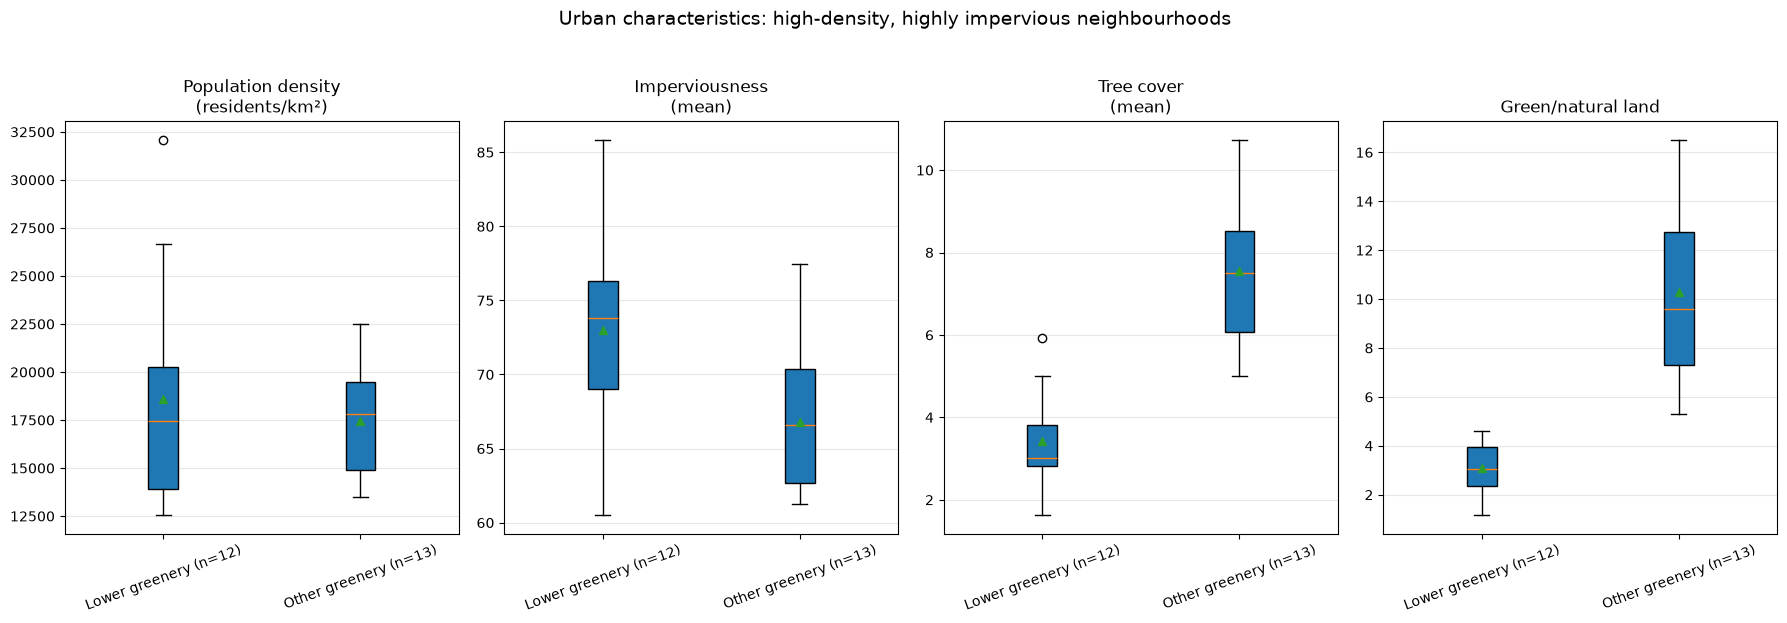

In [24]:
import matplotlib.pyplot as plt

# Define the indicators and their display labels
plot_cols = [
    "population_density_km2",
    "imperviousness_mean",
    "tree_cover_mean",
    "green_natural"
]

plot_labels = [
    "Population density\n(residents/km²)",
    "Imperviousness\n(mean)",
    "Tree cover\n(mean)",
    "Green/natural land"
]

# Prepare the two groups
groups = [lower_greenery, other_greenery]
group_labels = ["Lower greenery (n=12)", "Other greenery (n=13)"]

# Create four separate boxplots
fig, axes = plt.subplots(1, 4, figsize=(18, 6))

for ax, col, label in zip(axes, plot_cols, plot_labels):

    # Collect values for each group
    data = [group[col].dropna() for group in groups]

    # Draw the boxplots
    ax.boxplot(
        data,
        tick_labels=group_labels,
        patch_artist=True,
        showmeans=True
    )

    ax.set_title(label)
    ax.tick_params(axis="x", rotation=20)
    ax.grid(axis="y", alpha=0.3)

fig.suptitle(
    "Urban characteristics: high-density, highly impervious neighbourhoods",
    fontsize=14,
    y=1.03
)

plt.tight_layout()
plt.show()

Within the 25 neighbourhoods in the upper quartiles of population density and imperviousness, we identified 12 neighbourhoods that also fell into the lower quartiles for both tree cover and green/natural land. These were classified as the "Lower greenery" group. The remaining 13 neighbourhoods formed the "Other greenery" comparison group.

Despite similar population densities, the Lower greenery group showed higher median imperviousness and substantially lower median values for both greenery indicators.

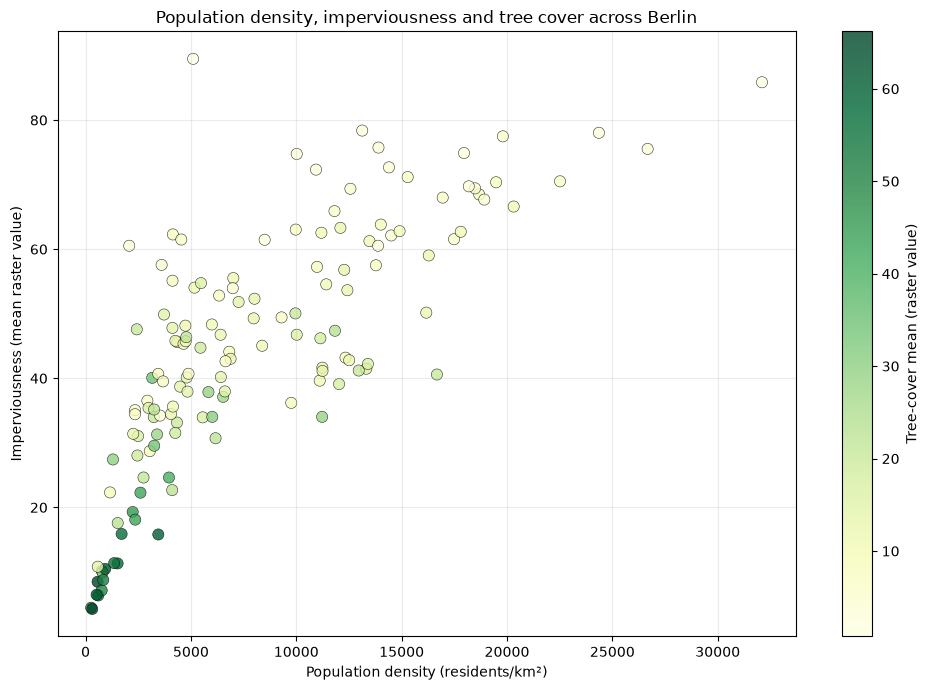

In [25]:
# Keep neighbourhoods with complete population density data
plot_df = urban_df.dropna(
    subset=["population_density_km2", "imperviousness_mean", "tree_cover_mean"]
)

# Create scatter plot
plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    plot_df["population_density_km2"],
    plot_df["imperviousness_mean"],
    c=plot_df["tree_cover_mean"],
    cmap="YlGn",
    s=65,
    alpha=0.8,
    edgecolors="black",
    linewidths=0.4
)

# Add labels and title
plt.xlabel("Population density (residents/km²)")
plt.ylabel("Imperviousness (mean raster value)")
plt.title("Population density, imperviousness and tree cover across Berlin")

# Add colour scale for tree cover
cbar = plt.colorbar(scatter)
cbar.set_label("Tree-cover mean (raster value)")

plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

Positive density–imperviousness relationship: This is consistent with the Spearman correlation of 0.802. More densely populated neighbourhoods generally tend to have higher imperviousness values.

Lower tree cover in denser areas: The colour pattern suggests that neighbourhoods with higher population density and imperviousness tend to have lower tree-cover values. This is consistent with the negative Spearman correlations:
- Density vs. tree cover: −0.580
- Imperviousness vs. tree cover: −0.788

High-density plateau: The plot appears to show that imperviousness remains relatively high across many densely populated neighbourhoods, rather than increasing indefinitely.

Two interesting outliers: The neighbourhood above 32,000 residents/km² and the one with approximately 90% imperviousness deserve further investigation.

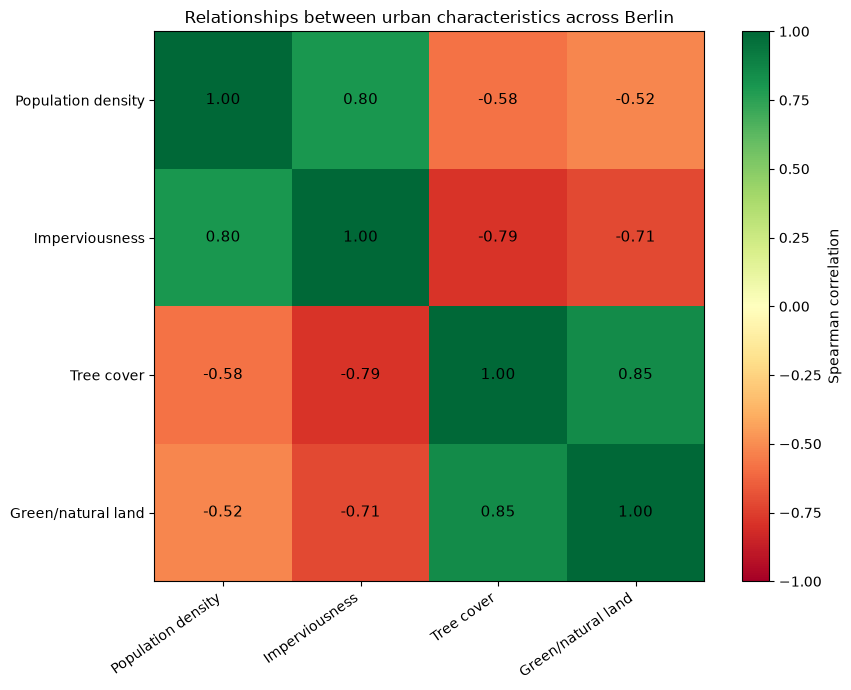

In [26]:
# Select indicators and calculate Spearman correlations
corr_cols = [
    "population_density_km2",
    "imperviousness_mean",
    "tree_cover_mean",
    "green_natural"
]

corr_matrix = urban_df[corr_cols].corr(method="spearman")

# Create readable axis labels
labels = [
    "Population density",
    "Imperviousness",
    "Tree cover",
    "Green/natural land"
]

# Draw the heatmap
fig, ax = plt.subplots(figsize=(9, 7))

image = ax.imshow(
    corr_matrix,
    cmap="RdYlGn",
    vmin=-1,
    vmax=1
)

# Add correlation values inside each cell
for i in range(len(labels)):
    for j in range(len(labels)):
        value = corr_matrix.iloc[i, j]
        ax.text(
            j, i,
            f"{value:.2f}",
            ha="center",
            va="center",
            fontsize=11
        )

# Set axis labels
ax.set_xticks(range(len(labels)))
ax.set_yticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=35, ha="right")
ax.set_yticklabels(labels)

# Add colour scale
cbar = plt.colorbar(image, ax=ax)
cbar.set_label("Spearman correlation")

ax.set_title("Relationships between urban characteristics across Berlin")
plt.tight_layout()
plt.show()

The correlation analysis reveals a clear relationship between Berlin's built environment and its vegetation patterns. Population density is strongly positively associated with imperviousness (Spearman ρ = 0.80), while imperviousness is strongly negatively associated with tree cover (ρ = −0.79). Tree cover and green/natural land also show a strong positive association (ρ = 0.85).

These patterns suggest that densely populated, highly sealed neighbourhoods tend to have less tree cover and less green/natural land. However, the correlations describe spatial associations and do not establish causal relationships.

In [28]:
# Select the 10 neighbourhoods with the highest population density
top_10_density = (
    urban_df
    .dropna(subset=["population_density_km2"])
    .nlargest(10, "population_density_km2")
    .sort_values("population_density_km2", ascending=True)
)

# Display the selected neighbourhoods and their indicators
top_10_density[
    [
        "bzr_name",
        "bez",
        "population_density_km2",
        "imperviousness_mean",
        "tree_cover_mean"
    ]
].round(2)

,bzr_name,bez,population_density_km2,imperviousness_mean,tree_cover_mean
64,Schöneberg Südwest,07 - Tempelhof-Schöneberg,18483.98,69.42,5.09
3,Brunnenstraße Süd,01 - Mitte,18679.65,68.48,7.93
80,Rixdorf,08 - Neukölln,18920.39,67.69,4.48
78,Neuköllner Mitte/Zentrum,08 - Neukölln,19482.19,70.36,7.51
32,Prenzlauer Berg Südwest,03 - Pankow,19804.45,77.48,5.12
33,Prenzlauer Berg Süd,03 - Pankow,20316.37,66.60,10.19
9,Wedding Zentrum,01 - Mitte,22515.30,70.51,6.45
16,Frankfurter Allee Nord,02 - Friedrichshain-Kreuzberg,24361.54,78.03,2.85
79,Reuterstraße,08 - Neukölln,26674.50,75.53,3.28
30,Helmholtzplatz,03 - Pankow,32100.38,85.86,1.64


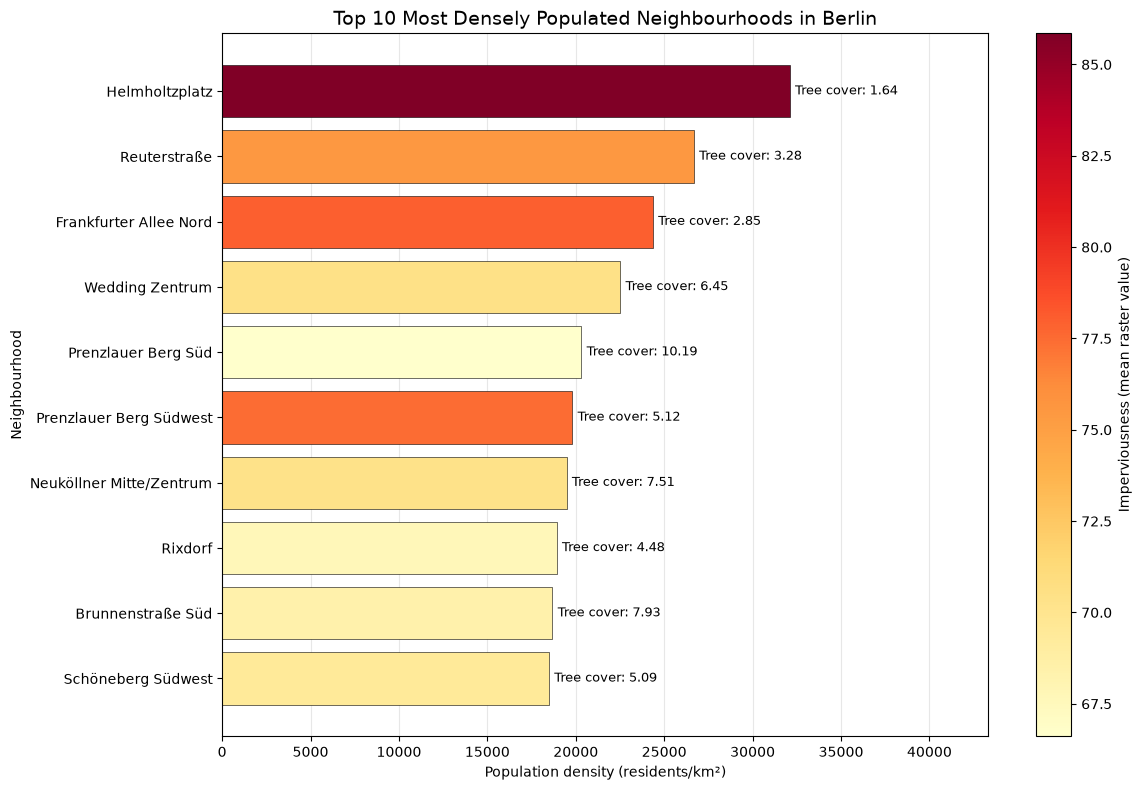

In [29]:
import matplotlib.colors as mcolors

# Set up the figure
fig, ax = plt.subplots(figsize=(12, 8))

# Colour bars according to imperviousness
norm = mcolors.Normalize(
    vmin=top_10_density["imperviousness_mean"].min(),
    vmax=top_10_density["imperviousness_mean"].max()
)

colors = plt.cm.YlOrRd(
    norm(top_10_density["imperviousness_mean"])
)

# Draw horizontal bars
bars = ax.barh(
    top_10_density["bzr_name"],
    top_10_density["population_density_km2"],
    color=colors,
    edgecolor="black",
    linewidth=0.4
)

# Add tree-cover values at the end of each bar
for bar, tree_value in zip(
    bars,
    top_10_density["tree_cover_mean"]
):
    ax.text(
        bar.get_width() + 300,
        bar.get_y() + bar.get_height() / 2,
        f"Tree cover: {tree_value:.2f}",
        va="center",
        fontsize=9
    )

# Add colour scale for imperviousness
sm = plt.cm.ScalarMappable(cmap="YlOrRd", norm=norm)
sm.set_array([])

cbar = plt.colorbar(sm, ax=ax)
cbar.set_label("Imperviousness (mean raster value)")

# Add titles and labels
ax.set_title(
    "Top 10 Most Densely Populated Neighbourhoods in Berlin",
    fontsize=14
)
ax.set_xlabel("Population density (residents/km²)")
ax.set_ylabel("Neighbourhood")

# Leave room for the tree-cover labels
ax.set_xlim(
    0,
    top_10_density["population_density_km2"].max() * 1.35
)

ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

Helmholtzplatz represents the most extreme case among Berlin's ten most densely populated neighbourhoods, combining approximately 32,100 residents/km² with the highest imperviousness mean (85.86) and lowest tree-cover mean (1.64) in this group.

However, the comparison also reveals variation among similarly dense neighbourhoods. Prenzlauer Berg Süd, for example, retains a considerably higher tree-cover mean (10.19), despite a population density exceeding 20,000 residents/km². This illustrates that densely populated neighbourhoods do not all share the same urban vegetation profile.

In [31]:
import geopandas as gpd

# Load the Berlin neighbourhood boundaries
lor_gdf = gpd.read_file("satellite_data/berlin_lor_2021.geojson")

# Inspect the dataset
print("Rows:", len(lor_gdf))
print("CRS:", lor_gdf.crs)
print("\nColumns:")
print(lor_gdf.columns.tolist())

print("\nFirst 5 rows:")
display(lor_gdf.head())

Rows: 143
CRS: EPSG:4326

Columns:
['id', 'bzr_id', 'bzr_name', 'pgr_id', 'pgr_name', 'bez', 'finhalt', 'stand', 'geometry']

First 5 rows:


,id,bzr_id,bzr_name,pgr_id,pgr_name,bez,finhalt,stand,geometry
0,b_lor_bzr_2021.011001,011001,Tiergarten Süd,0110,Zentrum,01 - Mitte,5.172481e+06,01.12.2021,"MULTIPOLYGON (((13.33601 52.51379, 13.33587 52..."
1,b_lor_bzr_2021.011002,011002,Regierungsviertel,0110,Zentrum,01 - Mitte,2.695511e+06,01.01.2021,"MULTIPOLYGON (((13.3765 52.51602, 13.37651 52...."
2,b_lor_bzr_2021.011003,011003,Alexanderplatz,0110,Zentrum,01 - Mitte,6.228825e+06,01.01.2021,"MULTIPOLYGON (((13.37357 52.52788, 13.37364 52..."
3,b_lor_bzr_2021.011004,011004,Brunnenstraße Süd,0110,Zentrum,01 - Mitte,1.755196e+06,01.01.2021,"MULTIPOLYGON (((13.39586 52.53809, 13.39569 52..."
4,b_lor_bzr_2021.012005,012005,Moabit West,0120,Moabit,01 - Mitte,4.305047e+06,01.01.2021,"MULTIPOLYGON (((13.33422 52.51677, 13.33431 52..."


In [32]:
# Standardise neighbourhood IDs as six-character strings
lor_gdf["bzr_id"] = lor_gdf["bzr_id"].astype(str).str.zfill(6)
urban_df["bzr_id"] = urban_df["bzr_id"].astype(str).str.zfill(6)

# Check for duplicate IDs before joining
print("Duplicate boundary IDs:", lor_gdf["bzr_id"].duplicated().sum())
print("Duplicate urban data IDs:", urban_df["bzr_id"].duplicated().sum())

# Join the indicators to the geographic boundaries
urban_map_gdf = lor_gdf.merge(
    urban_df,
    on="bzr_id",
    how="left",
    validate="one_to_one",
    indicator=True,
    suffixes=("_boundary", "_data")
)

# Check the join results
print("\nJoin results:")
print(urban_map_gdf["_merge"].value_counts())

print("\nUnmatched boundaries:")
display(
    urban_map_gdf.loc[
        urban_map_gdf["_merge"] != "both",
        ["bzr_id", "bzr_name_boundary"]
    ]
)

Duplicate boundary IDs: 0
Duplicate urban data IDs: 0

Join results:
_merge
both          143
left_only       0
right_only      0
Name: count, dtype: int64

Unmatched boundaries:


,bzr_id,bzr_name_boundary


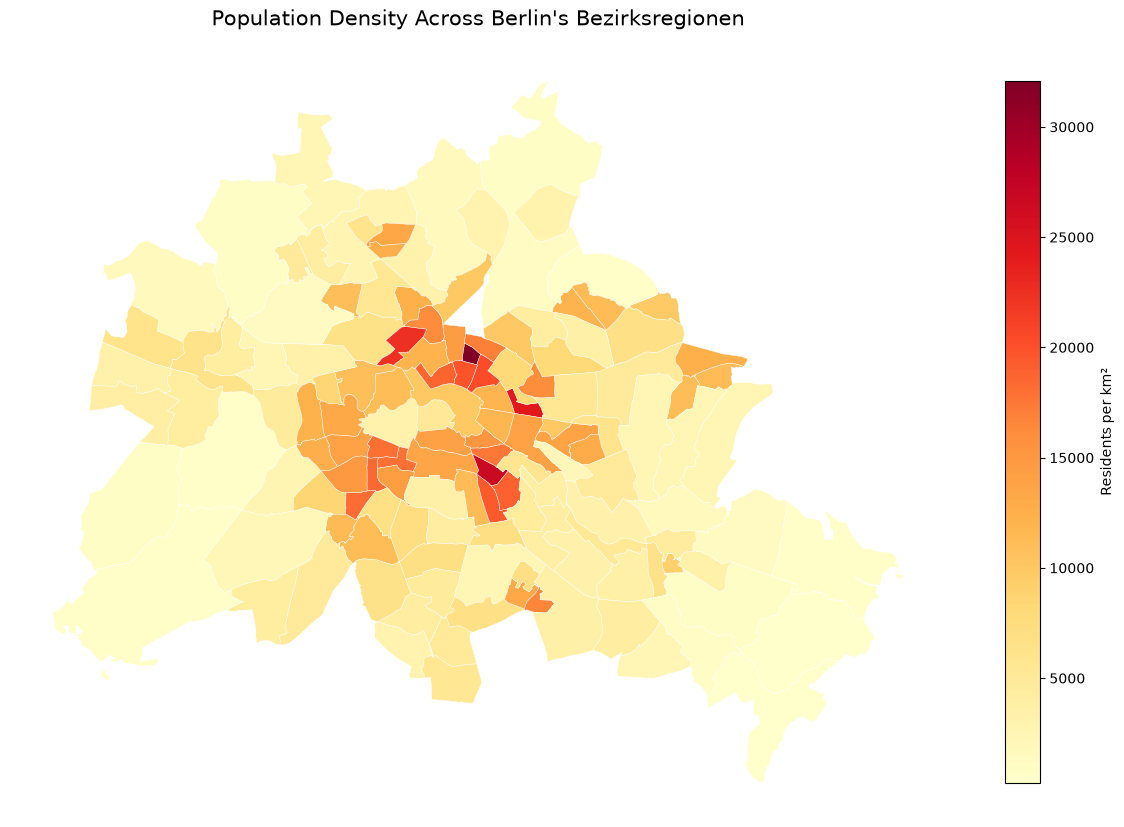

In [33]:
# Exclude neighbourhoods with missing population density
density_map = urban_map_gdf.dropna(
    subset=["population_density_km2"]
)

fig, ax = plt.subplots(figsize=(12, 12))

# Create the choropleth map
density_map.plot(
    column="population_density_km2",
    cmap="YlOrRd",
    linewidth=0.3,
    edgecolor="white",
    legend=True,
    legend_kwds={
        "label": "Residents per km²",
        "shrink": 0.6
    },
    ax=ax
)

ax.set_title(
    "Population Density Across Berlin's Bezirksregionen",
    fontsize=15,
    pad=15
)

ax.set_axis_off()

plt.tight_layout()
plt.show()

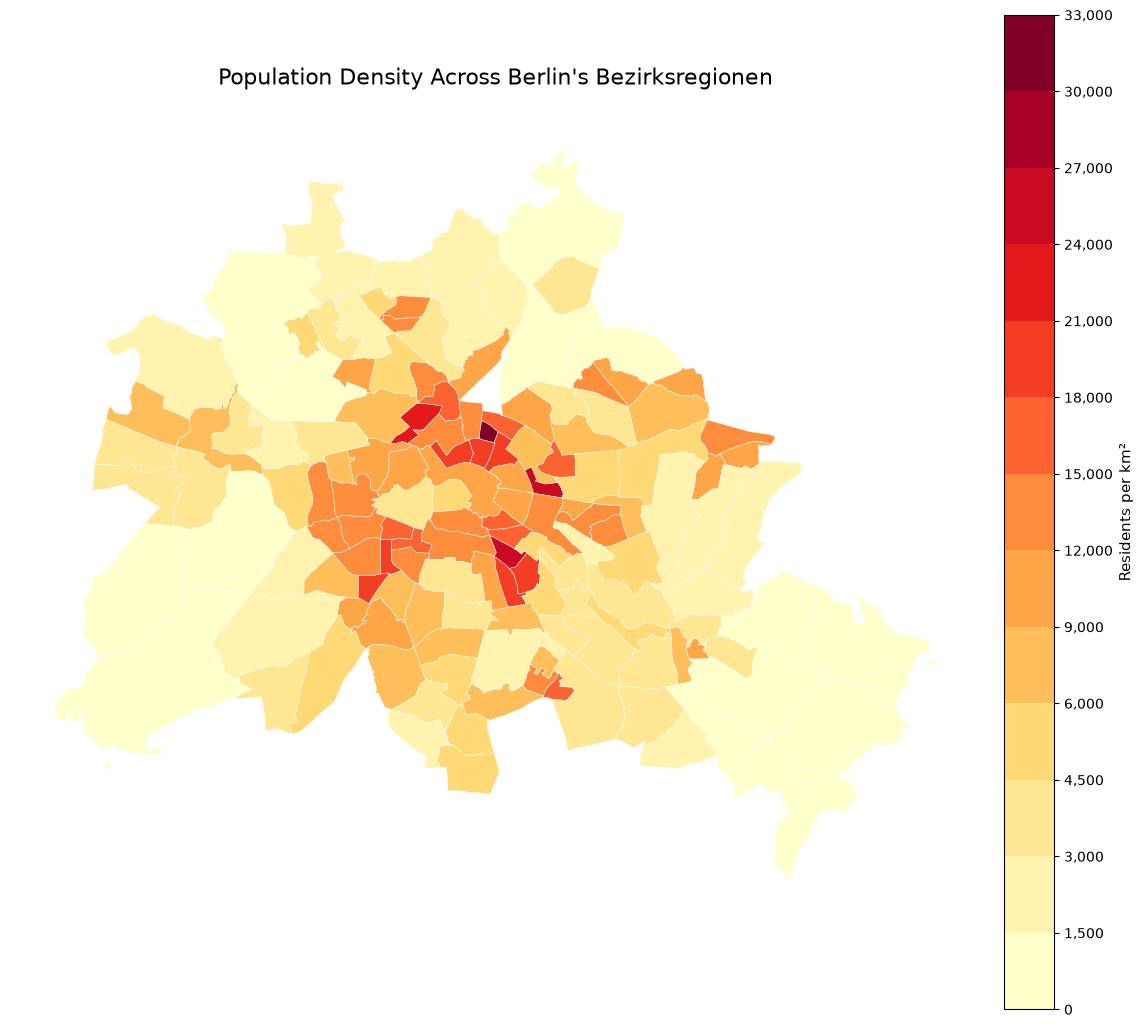

In [ ]:
import matplotlib.colors as mcolors
import matplotlib.ticker as ticker
import numpy as np

# Exclude missing population density values
density_map = urban_map_gdf.dropna(
    subset=["population_density_km2"]
)

# Use smaller intervals at the lower end
bounds = [0, 1500, 3000, 4500, 6000, 9000,
          12000, 15000, 18000, 21000, 24000,
          27000, 30000, 33000]

# Create a discrete colour scale
cmap = plt.get_cmap("YlOrRd", len(bounds) - 1)
norm = mcolors.BoundaryNorm(bounds, cmap.N)

fig, ax = plt.subplots(figsize=(12, 12))

# Plot population density
density_map.plot(
    column="population_density_km2",
    cmap=cmap,
    norm=norm,
    linewidth=0.35,
    edgecolor="white",
    ax=ax
)

# Add the colour legend
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=ax,
    boundaries=bounds,
    ticks=bounds,
    shrink=0.85,
    pad=0.02
)

cbar.ax.yaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, pos: f"{x:,.0f}")
)

cbar.set_label("Residents per km²", fontsize=11)

ax.set_title(
    "Population Density Across Berlin's Bezirksregionen",
    fontsize=16,
    pad=20
)

ax.set_axis_off()

plt.tight_layout()
plt.show()

1. Central concentration of high population density

The highest population densities, ranging from approximately 18,000 to over 30,000 residents/km², are concentrated in Berlin's inner-city neighbourhoods. Helmholtzplatz stands out as the most densely populated area, followed by other densely populated neighbourhoods in districts such as Friedrichshain-Kreuzberg, Neukölln and Mitte. This confirms the strong concentration of residents in central Berlin.

2. Lower population density in peripheral areas

The outer parts of Berlin are predominantly characterised by lower population densities, with many neighbourhoods falling below 3,000 residents/km². This contrasts sharply with the densely populated inner city and reflects Berlin's uneven spatial distribution of residents. Large green spaces, forests and water bodies may contribute to this pattern, although the population-density map alone does not establish their individual influence.

3. Intermediate-density areas beyond the city centre

Neighbourhoods with moderate population densities (approximately 9,000–15,000 residents/km²) form pockets between the densely populated centre and the lower-density periphery. These variations show that population density does not decline uniformly from the city centre towards the outskirts.

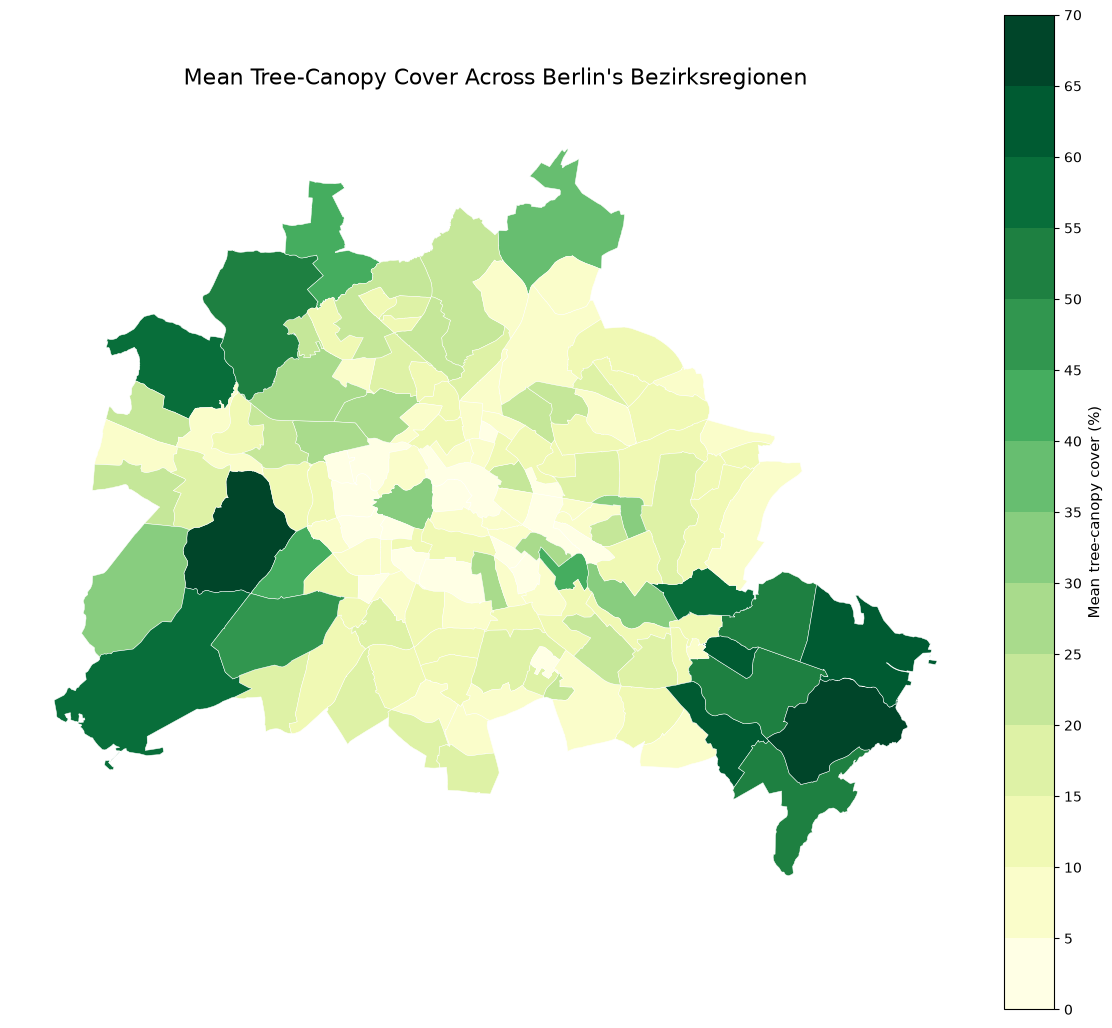

In [42]:
# Exclude missing tree-cover values
tree_map = urban_map_gdf.dropna(
    subset=["tree_cover_mean"]
)

# Define intervals every 5 percentage points
bounds = np.arange(0, 71, 5)

# Create a discrete green colour scale with more shades
cmap = plt.get_cmap("YlGn", len(bounds) - 1)
norm = mcolors.BoundaryNorm(bounds, cmap.N)

fig, ax = plt.subplots(figsize=(12, 12))

# Plot mean tree-canopy cover
tree_map.plot(
    column="tree_cover_mean",
    cmap=cmap,
    norm=norm,
    linewidth=0.35,
    edgecolor="white",
    ax=ax
)

# Add the colour legend
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=ax,
    boundaries=bounds,
    ticks=bounds,
    shrink=0.85,
    pad=0.02
)

cbar.ax.yaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, pos: f"{x:.0f}")
)

cbar.set_label("Mean tree-canopy cover (%)", fontsize=11)

# Add title and improve layout
ax.set_title(
    "Mean Tree-Canopy Cover Across Berlin's Bezirksregionen",
    fontsize=16,
    pad=20
)

ax.set_axis_off()

plt.tight_layout()
plt.show()

Key points:
- Greener outskirts: The highest mean canopy-cover values are concentrated in southeastern and western/southwestern Berlin, particularly around forested areas such as Köpenick, Grunewald and Wannsee.
- Less canopy in the urban core: Central neighbourhoods, including Mitte, Friedrichshain-Kreuzberg and parts of Neukölln, generally show lower mean tree-canopy cover.
- Intermediate transition zones: Parts of northern Berlin, including Pankow and Reinickendorf, display moderate levels of canopy cover.
- Uneven spatial distribution: Tree canopy varies considerably between neighbourhoods, highlighting differences in their urban environmental characteristics.

In [ ]:
#creating combined urban-exposure map

# Keep neighbourhoods with complete data
exposure_df = urban_df.dropna(
    subset=[
        "population_density_km2",
        "imperviousness_mean",
        "tree_cover_mean"
    ]
).copy()

# Check the number of neighbourhoods
print("Number of neighbourhoods:", len(exposure_df))

Number of neighbourhoods: 141


In [ ]:
# Calculate quartile thresholds

#Population density: upper quartile = relatively high.
#Imperviousness: upper quartile = relatively high.
#Tree-canopy cover: lower quartile = relatively low.


density_q3 = exposure_df["population_density_km2"].quantile(0.75)
impervious_q3 = exposure_df["imperviousness_mean"].quantile(0.75)
tree_cover_q1 = exposure_df["tree_cover_mean"].quantile(0.25)

# Identify neighbourhoods meeting all three criteria
exposure_df["high_density"] = (
    exposure_df["population_density_km2"] >= density_q3
)

exposure_df["high_imperviousness"] = (
    exposure_df["imperviousness_mean"] >= impervious_q3
)

exposure_df["low_tree_cover"] = (
    exposure_df["tree_cover_mean"] <= tree_cover_q1
)

# Combine the three conditions
exposure_df["high_urban_exposure"] = (
    exposure_df["high_density"] &
    exposure_df["high_imperviousness"] &
    exposure_df["low_tree_cover"]
)

# Check the thresholds and number of matching neighbourhoods
print("Population density Q3:", density_q3)
print("Imperviousness Q3:", impervious_q3)
print("Tree-cover Q1:", tree_cover_q1)

print(
    "Neighbourhoods meeting all three criteria:",
    exposure_df["high_urban_exposure"].sum()
)

Population density Q3: 12273.260042645876
Imperviousness Q3: 60.527451470465714
Tree-cover Q1: 7.158448309733577
Neighbourhoods meeting all three criteria: 18


In [45]:
# Select neighbourhoods meeting all three criteria
high_exposure_areas = (
    exposure_df[exposure_df["high_urban_exposure"]]
    .sort_values(
        "population_density_km2",
        ascending=False
    )
)

# Display the neighbourhoods and their indicators
high_exposure_areas[
    [
        "bzr_name",
        "population_density_km2",
        "imperviousness_mean",
        "tree_cover_mean"
    ]
].round(2)

,bzr_name,population_density_km2,imperviousness_mean,tree_cover_mean
30,Helmholtzplatz,32100.38,85.86,1.64
79,Reuterstraße,26674.50,75.53,3.28
16,Frankfurter Allee Nord,24361.54,78.03,2.85
9,Wedding Zentrum,22515.30,70.51,6.45
32,Prenzlauer Berg Südwest,19804.45,77.48,5.12
80,Rixdorf,18920.39,67.69,4.48
64,Schöneberg Südwest,18483.98,69.42,5.09
66,Friedenau West,18187.19,69.74,2.83
62,Schöneberg Nordwest,17959.02,74.90,2.80
13,Südliche Luisenstadt,17486.11,61.54,6.60


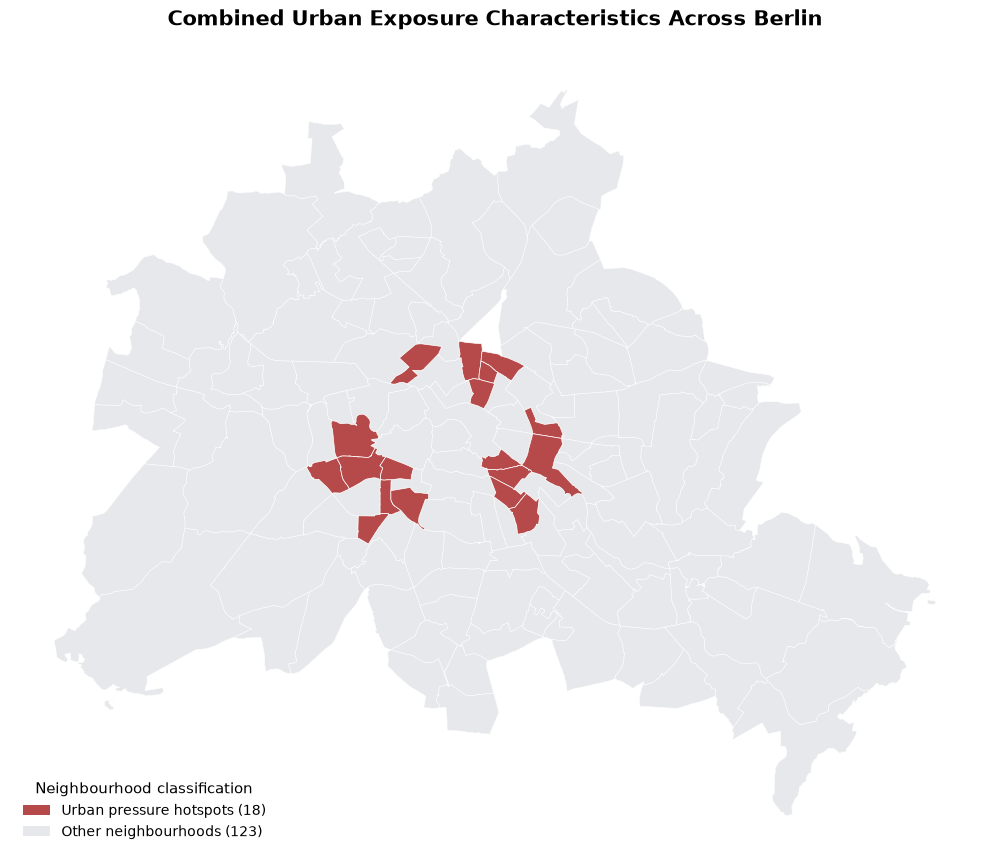

In [60]:
# Separate neighbourhoods by classification
selected = exposure_map_gdf[
    exposure_map_gdf["high_urban_exposure"] == True
]

not_selected = exposure_map_gdf[
    exposure_map_gdf["high_urban_exposure"] == False
]

# Create the map
fig, ax = plt.subplots(figsize=(10, 10))

# Plot neighbourhoods that do not meet all three criteria
not_selected.plot(
    color="#E6E8EB",
    edgecolor="white",
    linewidth=0.35,
    ax=ax
)

# Plot neighbourhoods that meet all three criteria
selected.plot(
    color="#B64A4A",
    edgecolor="white",
    linewidth=0.5,
    ax=ax
)

# legend
legend_items = [
    Patch(
        facecolor="#B64A4A",
        label=f"Urban pressure hotspots ({len(selected)})"
    ),
    Patch(
        facecolor="#E6E8EB",
        label=f"Other neighbourhoods ({len(not_selected)})"
    )
]

ax.legend(
    handles=legend_items,
    loc="lower left",
    frameon=False,
    fontsize=10,
    title="Neighbourhood classification",
    title_fontsize=11
)
# Add title
ax.set_title(
    "Combined Urban Exposure Characteristics Across Berlin",
    fontsize=15,
    fontweight="bold",
    pad=20
)

# Remove axes
ax.set_axis_off()

plt.tight_layout()
plt.show()


- 18 of 141 neighbourhoods (12.8%) combine high population density, high imperviousness and low tree-canopy cover.
- These neighbourhoods are predominantly concentrated in inner Berlin, particularly around and within the S-Bahn Ring.
- The pattern is not uniform: some central neighbourhoods do not meet all three criteria, highlighting differences in urban structure across the city.
- These areas could be prioritised for further investigation into urban heat exposure and potential green-infrastructure interventions.